# Integrated Smart-City Analytics for Mumbai
### Air quality • Weather • Seasonal patterns • Anomaly detection • Forecasting • Spatial comparison

**Objective:** explore urban environmental conditions in Mumbai using real public datasets, then apply Data Science lab techniques to identify patterns, unusual days, and short-term forecasting performance.


**Datasets targeted**
1. Kaggle — [Air Quality Data in India (2015–2020)](https://www.kaggle.com/datasets/rohanrao/air-quality-data-in-india). Use `city_day.csv` for city-level daily AQI/pollutants; filter to Mumbai.
2. Kaggle — [India Daily Weather and Air Quality](https://www.kaggle.com/datasets/akshaykarthickms007/india-daily-weather-and-air-quality). This dataset may require Kaggle authentication; the notebook attempts download and provides an upload fallback.
3. Supplementary official/open-data catalogue links for future extension: [Mumbai rainfall](https://www.data.opencity.in/dataset/mumbai-rainfall-data), [Mumbai hourly air-quality reports](https://data.opencity.in/dataset/mumbai-hourly-air-quality-reports), and [Mumbai mobility datasets](https://data.opencity.in/dataset/?_organization_limit=0&groups=mumbai&q=&sort=title_string+desc&tags=Mobility).



## 1. Install and import libraries


In [ ]:
!pip -q install kagglehub pandas numpy matplotlib seaborn scikit-learn statsmodels

In [ ]:
import os, glob, warnings, zipfile, shutil, pathlib, json, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")
sns.set_theme()
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
RANDOM_STATE = 42
DATA_DIR = "/content/smart_city_data"
os.makedirs(DATA_DIR, exist_ok=True)

print("Python data-science environment ready.")
print("Data directory:", DATA_DIR)

Python data-science environment ready.
Data directory: /content/smart_city_data


## 2. Download Kaggle datasets

In [ ]:
download_log = []

def try_kagglehub_download(dataset_slug, dest):
    try:
        import kagglehub
        path = kagglehub.dataset_download(dataset_slug)
        download_log.append({"dataset": dataset_slug, "status": "downloaded", "path": path})
        print(f"Downloaded {dataset_slug} to: {path}")
        return path
    except Exception as e:
        download_log.append({"dataset": dataset_slug, "status": "failed", "error": str(e)[:300]})
        print(f"Could not download {dataset_slug}. This can be due to Kaggle authentication/terms.")
        print("Reason:", str(e)[:300])
        return None

aqi_path = try_kagglehub_download("rohanrao/air-quality-data-in-india", DATA_DIR)
weather_path = try_kagglehub_download("akshaykarthickms007/india-daily-weather-and-air-quality", DATA_DIR)

# Copy discovered CSVs into a common folder for easier file discovery
for p in [aqi_path, weather_path]:
    if p and os.path.isdir(p):
        for f in glob.glob(os.path.join(p, "**", "*.csv"), recursive=True):
            target = os.path.join(DATA_DIR, os.path.basename(f))
            if os.path.abspath(f) != os.path.abspath(target):
                try:
                    if not os.path.exists(target):
                        shutil.copy2(f, target)
                except Exception:
                    pass

pd.DataFrame(download_log)

Using Colab cache for faster access to the 'air-quality-data-in-india' dataset.
Downloaded rohanrao/air-quality-data-in-india to: /kaggle/input/air-quality-data-in-india


100%|██████████| 5.02M/5.02M [00:00<00:00, 117MB/s]

Extracting files...


Downloaded akshaykarthickms007/india-daily-weather-and-air-quality to: /root/.cache/kagglehub/datasets/akshaykarthickms007/india-daily-weather-and-air-quality/versions/37


,dataset,status,path
0,rohanrao/air-quality-data-in-india,downloaded,/kaggle/input/air-quality-data-in-india
1,akshaykarthickms007/india-daily-weather-and-ai...,downloaded,/root/.cache/kagglehub/datasets/akshaykarthick...


## 3. Upload CSV files if Kaggle download did not work


In [ ]:
try:
    from google.colab import files
    existing_csvs = glob.glob(os.path.join(DATA_DIR, "*.csv"))
    print("CSV files already available:", [os.path.basename(f) for f in existing_csvs])
    if not existing_csvs:
        print("Upload the Kaggle CSV file(s) now.")
        uploaded = files.upload()
        for name, content in uploaded.items():
            with open(os.path.join(DATA_DIR, os.path.basename(name)), "wb") as out:
                out.write(content)
        print("Uploaded:", list(uploaded.keys()))
    else:
        print("Skipping upload. If you need to add more files, run this cell after removing/renaming existing files.")
except Exception as e:
    print("Colab upload widget unavailable in this environment.")
    print("Upload CSVs manually to", DATA_DIR, "and rerun this cell. Details:", e)

CSV files already available: ['stations.csv', 'air_quality_daily.csv', 'weather_daily.csv', 'station_day.csv', 'city_hour.csv', 'station_hour.csv', 'city_day.csv', 'cities.csv']
Skipping upload. If you need to add more files, run this cell after removing/renaming existing files.


## 4. Inventory files and inspect schemas


In [ ]:
csv_files = glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)
file_inventory = []
loaded_tables = {}
for f in sorted(set(csv_files)):
    try:
        df_tmp = pd.read_csv(f, low_memory=False)
        file_inventory.append({
            "file": os.path.relpath(f, DATA_DIR),
            "rows": len(df_tmp),
            "columns": len(df_tmp.columns),
            "size_MB": round(os.path.getsize(f)/1e6, 2),
            "column_names": ", ".join(map(str, df_tmp.columns[:30]))
        })
        loaded_tables[os.path.basename(f).lower()] = df_tmp
    except Exception as e:
        file_inventory.append({"file": os.path.relpath(f, DATA_DIR), "error": str(e)[:200]})

inventory_df = pd.DataFrame(file_inventory)
display(inventory_df)
print("\nAvailable CSV basenames:", list(loaded_tables.keys()))

,file,rows,columns,size_MB,column_names
0,air_quality_daily.csv,77250,19,8.64,"date, city, pm2_5_mean, pm2_5_max, pm10_mean, ..."
1,cities.csv,50,6,0.00,"city, state, region, latitude, longitude, elev..."
2,city_day.csv,29531,16,2.57,"City, Date, PM2.5, PM10, NO, NO2, NOx, NH3, CO..."
3,city_hour.csv,707875,16,65.65,"City, Datetime, PM2.5, PM10, NO, NO2, NOx, NH3..."
4,station_day.csv,108035,16,8.63,"StationId, Date, PM2.5, PM10, NO, NO2, NOx, NH..."
5,station_hour.csv,2589083,16,219.68,"StationId, Datetime, PM2.5, PM10, NO, NO2, NOx..."
6,stations.csv,230,5,0.01,"StationId, StationName, City, State, Status"
7,weather_daily.csv,124600,14,9.02,"date, city, temperature_2m_max, temperature_2m..."



Available CSV basenames: ['air_quality_daily.csv', 'cities.csv', 'city_day.csv', 'city_hour.csv', 'station_day.csv', 'station_hour.csv', 'stations.csv', 'weather_daily.csv']


## 5. Identify AQI and weather tables robustly


In [ ]:
def find_table(keywords, required_columns=None):
    # Prefer the compact daily datasets for this notebook; avoid huge hourly files unless needed.
    for name, df in loaded_tables.items():
        if any(k in name for k in keywords):
            return df.copy(), name
    if required_columns:
        for name, df in loaded_tables.items():
            cols = {str(c).strip().lower() for c in df.columns}
            if all(any(req in c for c in cols) for req in required_columns):
                return df.copy(), name
    return None, None

# The downloaded Kaggle bundle includes air_quality_daily.csv, weather_daily.csv,
# and the classic city_day.csv. Prefer air_quality_daily because it has Mumbai rows
# and daily AQI/pollutant fields with a consistent 2022+ schema.
aqi_raw, aqi_filename = find_table(["air_quality_daily", "city_day", "aqi_daily", "mumbai_aqi"])
if aqi_raw is None:
    aqi_raw, aqi_filename = find_table(["air_quality", "aqi"], required_columns=["date", "city"])

weather_raw, weather_filename = find_table(["weather_daily", "daily_weather", "weather"])

print("Selected AQI table:", aqi_filename, None if aqi_raw is None else aqi_raw.shape)
print("Selected weather table:", weather_filename, None if weather_raw is None else weather_raw.shape)

def normalize_colnames(df):
    out = df.copy()
    out.columns = [str(c).strip().replace(" ", "_") for c in out.columns]
    return out

if aqi_raw is not None:
    aqi_raw = normalize_colnames(aqi_raw)
    print("AQI source columns:", list(aqi_raw.columns))
if weather_raw is not None:
    weather_raw = normalize_colnames(weather_raw)
    print("Weather source columns:", list(weather_raw.columns))

Selected AQI table: air_quality_daily.csv (77250, 19)
Selected weather table: weather_daily.csv (124600, 14)
AQI source columns: ['date', 'city', 'pm2_5_mean', 'pm2_5_max', 'pm10_mean', 'pm10_max', 'no2_mean', 'so2_mean', 'o3_8h_max', 'co_8h_max', 'dust_mean', 'aod_mean', 'us_aqi_max', 'hours_available', 'india_aqi', 'india_aqi_category', 'dominant_pollutant', 'india_aqi_pm', 'india_aqi_pm_category']
Weather source columns: ['date', 'city', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'apparent_temperature_max', 'precipitation_sum', 'precipitation_hours', 'relative_humidity_2m_mean', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'weather_code']


## 6. Clean and filter Mumbai AQI data


In [ ]:
aqi = None
if aqi_raw is not None:
    raw = aqi_raw.copy()
    lower_map = {str(c).strip().lower(): c for c in raw.columns}

    city_col = next((lower_map[c] for c in ["city", "city_name", "location"] if c in lower_map), None)
    date_col = next((lower_map[c] for c in ["date", "datetime", "timestamp"] if c in lower_map), None)

    # Normalize known Kaggle schemas to one consistent set of analysis column names.
    aliases = {
        "india_aqi": "AQI",
        "us_aqi_max": "US_AQI",
        "india_aqi_category": "AQI_Bucket",
        "india_aqi_pm_category": "AQI_PM_Bucket",
        "pm2_5_mean": "PM2.5",
        "pm2_5_max": "PM2.5_max",
        "pm10_mean": "PM10",
        "pm10_max": "PM10_max",
        "no2_mean": "NO2",
        "so2_mean": "SO2",
        "o3_8h_max": "O3",
        "co_8h_max": "CO",
        "dust_mean": "Dust",
        "aod_mean": "AOD",
        "dominant_pollutant": "Dominant_Pollutant",
    }
    rename = {}
    for c in raw.columns:
        key = str(c).strip().lower()
        if key in aliases:
            rename[c] = aliases[key]
    raw = raw.rename(columns=rename)

    # Standardize date and filter to Mumbai if city is available.
    if date_col is not None:
        date_actual = rename.get(date_col, date_col)
        raw[date_actual] = pd.to_datetime(raw[date_actual], errors="coerce")
        raw = raw.dropna(subset=[date_actual]).rename(columns={date_actual: "date"})
    if city_col is not None:
        city_actual = rename.get(city_col, city_col)
        raw[city_actual] = raw[city_actual].astype(str).str.strip()
        raw = raw.loc[raw[city_actual].str.contains("Mumbai", case=False, na=False)].copy()
    elif "mumbai" not in str(aqi_filename).lower():
        print("Warning: selected AQI file has no city column; cannot verify that it is Mumbai-only.")

    # Force relevant measures to numeric, leaving categorical labels as strings.
    numeric_candidates = ["AQI", "US_AQI", "PM2.5", "PM2.5_max", "PM10", "PM10_max",
                          "NO2", "SO2", "O3", "CO", "Dust", "AOD", "hours_available",
                          "india_aqi_pm"]
    for c in numeric_candidates:
        if c in raw.columns:
            raw[c] = pd.to_numeric(raw[c], errors="coerce")

    if "date" in raw.columns:
        raw = raw.sort_values("date").drop_duplicates(subset=["date"], keep="last")
    aqi = raw.copy()

if aqi is not None and len(aqi):
    print("Mumbai AQI rows:", len(aqi), "| date range:", aqi["date"].min(), "to", aqi["date"].max())
    print("Standardized columns:", aqi.columns.tolist())
    display(aqi.head())
else:
    print("No usable Mumbai AQI records were found. Confirm that air_quality_daily.csv is present and contains Mumbai rows.")

Mumbai AQI rows: 1545 | date range: 2022-08-05 00:00:00 to 2026-10-27 00:00:00
Standardized columns: ['date', 'city', 'PM2.5', 'PM2.5_max', 'PM10', 'PM10_max', 'NO2', 'SO2', 'O3', 'CO', 'Dust', 'AOD', 'US_AQI', 'hours_available', 'AQI', 'AQI_Bucket', 'Dominant_Pollutant', 'india_aqi_pm', 'AQI_PM_Bucket']


,date,city,PM2.5,PM2.5_max,PM10,PM10_max,NO2,SO2,O3,CO,Dust,AOD,US_AQI,hours_available,AQI,AQI_Bucket,Dominant_Pollutant,india_aqi_pm,AQI_PM_Bucket
44805,2022-08-05,Mumbai,16.74,31.8,25.29,46.8,27.19,39.76,66.62,473.25,1.46,0.30,77.0,24,67,Satisfactory,O3,28,Good
44806,2022-08-06,Mumbai,18.98,40.2,29.47,60.5,24.08,36.63,73.12,491.00,1.50,0.28,69.0,24,73,Satisfactory,O3,32,Good
44807,2022-08-07,Mumbai,17.84,31.3,28.71,49.0,20.32,26.98,74.62,391.00,1.71,0.30,71.0,24,75,Satisfactory,O3,30,Good
44808,2022-08-08,Mumbai,18.38,25.9,29.40,40.7,22.82,26.93,43.12,355.50,0.88,0.27,68.0,24,43,Good,O3,31,Good
44809,2022-08-09,Mumbai,20.21,28.5,33.22,47.5,16.22,23.33,55.50,368.25,0.29,0.26,71.0,24,56,Satisfactory,O3,34,Good


## 7. Clean and filter weather data


In [ ]:
weather = None
if weather_raw is not None:
    weather = weather_raw.copy()
    lower_map_w = {str(c).strip().lower(): c for c in weather.columns}
    city_col_w = next((lower_map_w[c] for c in ["city", "city_name", "location"] if c in lower_map_w), None)
    date_col_w = next((lower_map_w[c] for c in ["date", "datetime", "time", "timestamp"] if c in lower_map_w), None)

    if city_col_w is not None:
        weather[city_col_w] = weather[city_col_w].astype(str).str.strip()
        weather = weather.loc[weather[city_col_w].str.contains("Mumbai", case=False, na=False)].copy()

    if date_col_w is not None:
        weather[date_col_w] = pd.to_datetime(weather[date_col_w], errors="coerce")
        weather = weather.dropna(subset=[date_col_w]).rename(columns={date_col_w: "date"})

    if "date" in weather.columns:
        weather = weather.sort_values("date").drop_duplicates(subset=["date"], keep="last")

    # Ensure known weather measures are numeric.
    for c in weather.columns:
        if c != "date" and c != city_col_w:
            weather[c] = pd.to_numeric(weather[c], errors="ignore")

    print("Mumbai weather rows:", len(weather))
    if "date" in weather.columns and len(weather):
        print("Date range:", weather["date"].min(), "to", weather["date"].max())
    print("Weather columns:", weather.columns.tolist())
    display(weather.head())
else:
    print("No weather table detected; weather-specific charts will be skipped.")

Mumbai weather rows: 2492
Date range: 2020-01-01 00:00:00 to 2026-10-27 00:00:00
Weather columns: ['date', 'city', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'apparent_temperature_max', 'precipitation_sum', 'precipitation_hours', 'relative_humidity_2m_mean', 'wind_speed_10m_max', 'wind_direction_10m_dominant', 'shortwave_radiation_sum', 'et0_fao_evapotranspiration', 'weather_code']


,date,city,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,precipitation_sum,precipitation_hours,relative_humidity_2m_mean,wind_speed_10m_max,wind_direction_10m_dominant,shortwave_radiation_sum,et0_fao_evapotranspiration,weather_code
72268,2020-01-01,Mumbai,25.9,15.6,20.9,27.7,0.0,0.0,75,13.2,350,17.02,3.40,0
72269,2020-01-02,Mumbai,26.7,17.7,21.9,27.4,0.0,0.0,77,16.1,337,16.75,3.42,3
72270,2020-01-03,Mumbai,26.5,18.5,21.8,27.6,0.0,0.0,75,23.5,348,16.92,3.74,3
72271,2020-01-04,Mumbai,25.9,18.3,21.6,25.8,0.0,0.0,67,21.4,345,17.23,4.03,3
72272,2020-01-05,Mumbai,29.7,18.4,23.1,31.4,0.0,0.0,66,16.8,30,17.00,4.18,0


## 8. Data quality and missingness audit


In [ ]:
if aqi is not None and len(aqi):
    print("AQI dataset shape:", aqi.shape)
    print("Duplicate dates:", aqi["date"].duplicated().sum())
    missing_pct = (aqi.isna().mean()*100).sort_values(ascending=False)
    display(missing_pct.rename("missing_percent").to_frame().round(2))
    numeric_aqi_cols = aqi.select_dtypes(include=np.number).columns.tolist()
    if numeric_aqi_cols:
        display(aqi[numeric_aqi_cols].describe().T.round(2))
else:
    print("AQI quality audit skipped because no AQI data is loaded.")

AQI dataset shape: (1545, 19)
Duplicate dates: 0


,missing_percent
date,0.0
city,0.0
PM2.5,0.0
PM2.5_max,0.0
PM10,0.0
PM10_max,0.0
NO2,0.0
SO2,0.0
O3,0.0
CO,0.0


,count,mean,std,min,25%,50%,75%,max
PM2.5,1545.0,40.15,28.96,0.75,19.70,28.42,55.41,279.78
PM2.5_max,1545.0,58.50,53.23,1.00,24.90,39.60,75.40,581.10
PM10,1545.0,62.52,37.37,1.06,38.65,51.59,76.94,403.34
PM10_max,1545.0,89.40,71.49,1.40,50.20,68.00,100.60,832.60
NO2,1545.0,21.42,18.67,0.00,9.28,15.78,25.00,116.25
SO2,1545.0,28.80,26.76,0.28,10.59,23.16,32.52,170.02
O3,1545.0,163.18,94.88,29.25,82.00,147.00,223.38,715.88
CO,1545.0,572.17,381.06,59.62,263.75,496.75,756.88,2912.38
Dust,1545.0,20.16,23.42,0.00,2.33,12.21,29.92,156.75
AOD,1545.0,0.50,0.23,0.04,0.33,0.46,0.63,1.53


# Exploratory Data Analysis: visualizations with inferences


## Visualization 1 — Daily AQI over time
**Purpose:** identify long-term changes, high-pollution episodes, and data gaps.

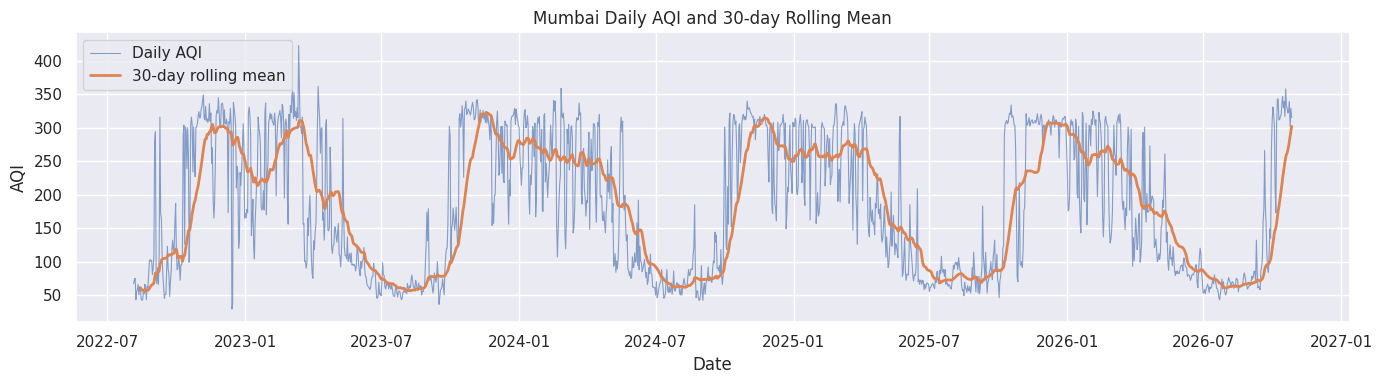

Inference: compare the rolling mean across years. Persistent elevation indicates sustained poorer air quality; isolated spikes indicate episodic pollution. Check coverage/missingness before claiming a trend.


In [ ]:
if aqi is not None and "AQI" in aqi.columns and aqi["AQI"].notna().sum() > 2:
    daily = aqi[["date", "AQI"]].dropna().sort_values("date")
    plt.figure(figsize=(14, 4))
    plt.plot(daily["date"], daily["AQI"], linewidth=0.8, alpha=0.65, label="Daily AQI")
    plt.plot(daily["date"], daily["AQI"].rolling(30, min_periods=10).mean(), linewidth=2, label="30-day rolling mean")
    plt.title("Mumbai Daily AQI and 30-day Rolling Mean")
    plt.xlabel("Date"); plt.ylabel("AQI"); plt.legend(); plt.tight_layout(); plt.show()
    print("Inference: compare the rolling mean across years. Persistent elevation indicates sustained poorer air quality; isolated spikes indicate episodic pollution. Check coverage/missingness before claiming a trend.")
else:
    print("Skipped: AQI column not available or insufficient non-missing AQI values.")

## Visualization 2 — AQI category distribution
**Purpose:** understand how often observed days fall into each reported AQI category. This uses the dataset's `AQI_Bucket` when available; it does not re-label categories unless that column is absent.

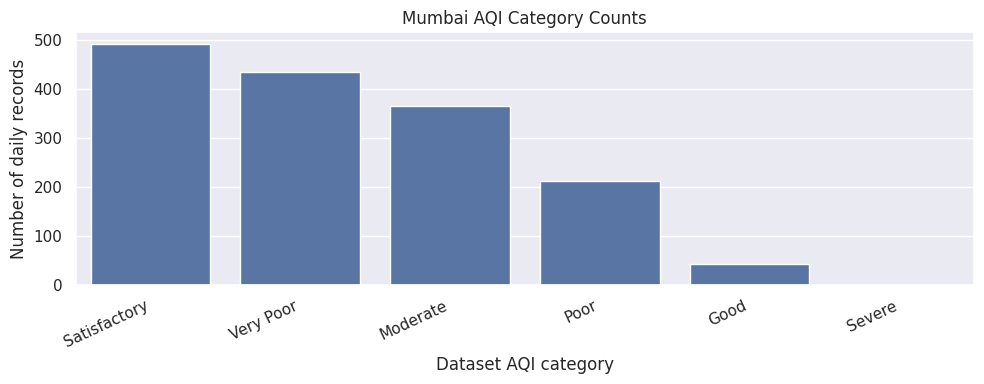

Inference: categories with more records represent the most commonly observed conditions in this dataset's coverage period. This is not automatically a full-year or population-weighted estimate.


In [ ]:
if aqi is not None:
    bucket_col = next((c for c in aqi.columns if c.lower() in ["aqi_bucket", "aqi_category", "category"]), None)
    if bucket_col:
        counts = aqi[bucket_col].fillna("Missing").value_counts()
        plt.figure(figsize=(10, 4))
        sns.barplot(x=counts.index.astype(str), y=counts.values)
        plt.title("Mumbai AQI Category Counts")
        plt.xlabel("Dataset AQI category"); plt.ylabel("Number of daily records")
        plt.xticks(rotation=25, ha="right"); plt.tight_layout(); plt.show()
        print("Inference: categories with more records represent the most commonly observed conditions in this dataset's coverage period. This is not automatically a full-year or population-weighted estimate.")
    elif "AQI" in aqi.columns:
        vals = aqi["AQI"].dropna()
        if len(vals):
            plt.figure(figsize=(8, 4))
            plt.hist(vals, bins=30, edgecolor="black")
            plt.title("Distribution of Daily AQI Values — Mumbai")
            plt.xlabel("AQI"); plt.ylabel("Frequency"); plt.tight_layout(); plt.show()
            print("Inference: right-skew and extreme values indicate occasional high-pollution episodes. Compare with time-series plots to see when these occurred.")
        else: print("Skipped: no valid AQI values.")
    else: print("Skipped: neither AQI category nor AQI numeric column is available.")
else: print("Skipped: AQI data not loaded.")

## Visualization 3 — Pollutant correlation heatmap
**Purpose:** explore co-movement among pollutant measurements. Correlation does not establish causation and may be affected by missingness and shared monitoring patterns.

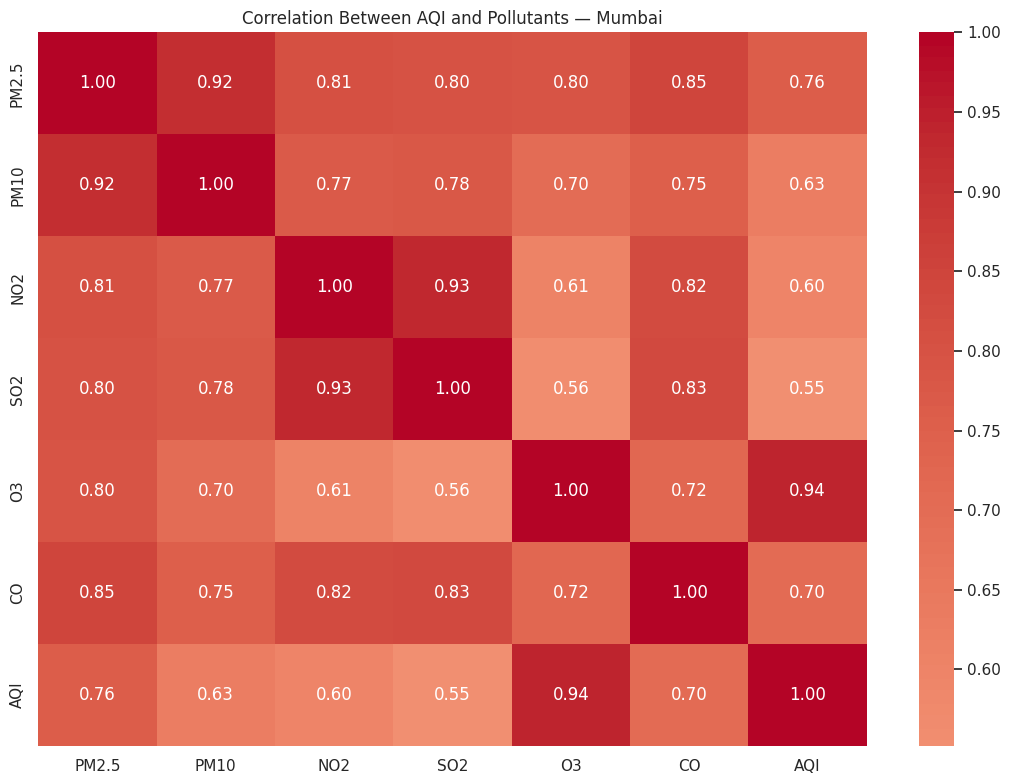

Inference: strong positive correlations suggest pollutants tend to rise together in this dataset. AQI is often calculated from pollutant concentrations, so correlation with AQI is partly expected.


In [ ]:
if aqi is not None:
    pollutant_candidates = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene", "AQI"]
    pollutant_cols = [c for c in aqi.columns if c.upper().replace(".", "").replace("_", "") in
                      [x.upper().replace(".", "").replace("_", "") for x in pollutant_candidates]]
    pollutant_cols = [c for c in pollutant_cols if pd.api.types.is_numeric_dtype(aqi[c])]
    if len(pollutant_cols) >= 2:
        corr = aqi[pollutant_cols].corr(min_periods=10)
        plt.figure(figsize=(11, 8))
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=False)
        plt.title("Correlation Between AQI and Pollutants — Mumbai")
        plt.tight_layout(); plt.show()
        print("Inference: strong positive correlations suggest pollutants tend to rise together in this dataset. AQI is often calculated from pollutant concentrations, so correlation with AQI is partly expected.")
    else: print("Skipped: fewer than two numeric pollutant columns were found.")
else: print("Skipped: AQI data not loaded.")

## Visualization 4 — Pollutant distributions
**Purpose:** compare spread and outliers across available pollutant variables. Extreme values should be investigated, not automatically removed.

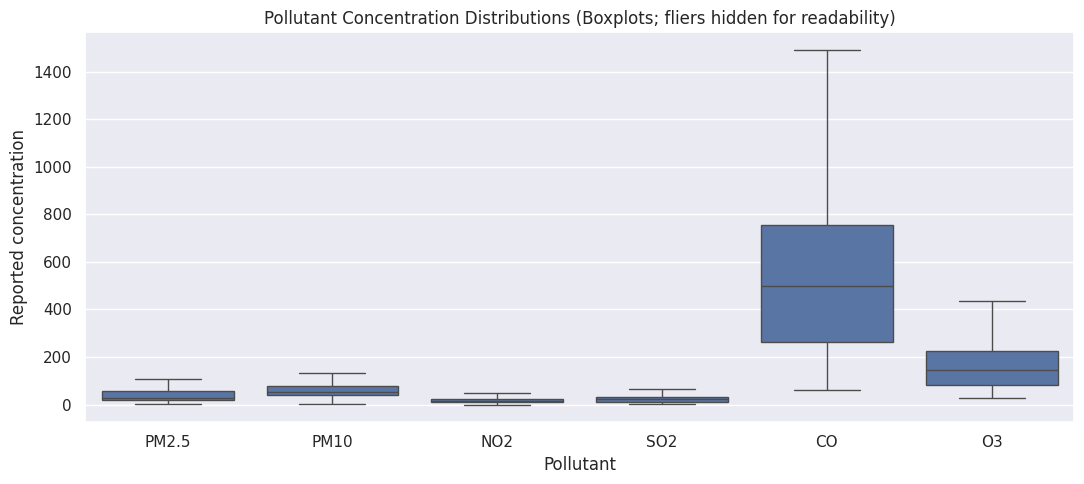

Inference: compare medians and interquartile ranges within each pollutant. Concentration units differ by pollutant, so avoid directly ranking pollutants by raw magnitude.


In [ ]:
if aqi is not None:
    pollutant_order = [c for c in ["PM2.5", "PM10", "NO2", "SO2", "CO", "O3"] if c in aqi.columns and pd.api.types.is_numeric_dtype(aqi[c])]
    if pollutant_order:
        longp = aqi[pollutant_order].melt(var_name="Pollutant", value_name="Concentration").dropna()
        plt.figure(figsize=(11, 5))
        sns.boxplot(data=longp, x="Pollutant", y="Concentration", showfliers=False)
        plt.title("Pollutant Concentration Distributions (Boxplots; fliers hidden for readability)")
        plt.xlabel("Pollutant"); plt.ylabel("Reported concentration")
        plt.tight_layout(); plt.show()
        print("Inference: compare medians and interquartile ranges within each pollutant. Concentration units differ by pollutant, so avoid directly ranking pollutants by raw magnitude.")
    else: print("Skipped: common numeric pollutant columns not found.")
else: print("Skipped: AQI data not loaded.")

## Visualization 5 — Monthly seasonality of AQI
**Purpose:** compare typical AQI by calendar month. This can reveal seasonal patterns, but it does not prove a specific cause (for example, monsoon washout or festival emissions).

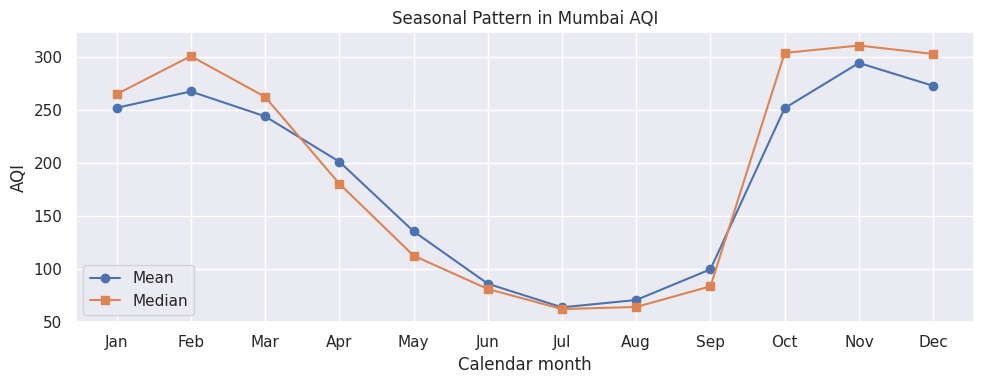

,mean,median,count
month,,,
1,252.13,265.0,124
2,267.59,301.0,113
3,244.10,262.5,124
4,201.28,180.5,120
5,135.52,112.5,124
6,85.96,81.0,120
7,63.63,62.0,124
8,70.58,64.0,151
9,99.58,83.5,150


Inference: higher monthly means identify months with worse average AQI in the available years. Check monthly counts so missing months do not mislead.


In [ ]:
if aqi is not None and "AQI" in aqi.columns and aqi["AQI"].notna().sum() > 10:
    temp = aqi[["date", "AQI"]].dropna().copy()
    temp["month"] = temp["date"].dt.month
    month_mean = temp.groupby("month")["AQI"].agg(["mean", "median", "count"]).reindex(range(1,13))
    plt.figure(figsize=(10, 4))
    plt.plot(month_mean.index, month_mean["mean"], marker="o", label="Mean")
    plt.plot(month_mean.index, month_mean["median"], marker="s", label="Median")
    plt.xticks(range(1,13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
    plt.title("Seasonal Pattern in Mumbai AQI")
    plt.xlabel("Calendar month"); plt.ylabel("AQI"); plt.legend(); plt.tight_layout(); plt.show()
    display(month_mean.round(2))
    print("Inference: higher monthly means identify months with worse average AQI in the available years. Check monthly counts so missing months do not mislead.")
else: print("Skipped: AQI time series unavailable.")

## Visualization 6 — Weather time series
**Purpose:** display daily temperature and/or precipitation to contextualize urban environmental conditions. Column names vary by dataset; the code selects recognized fields when present.

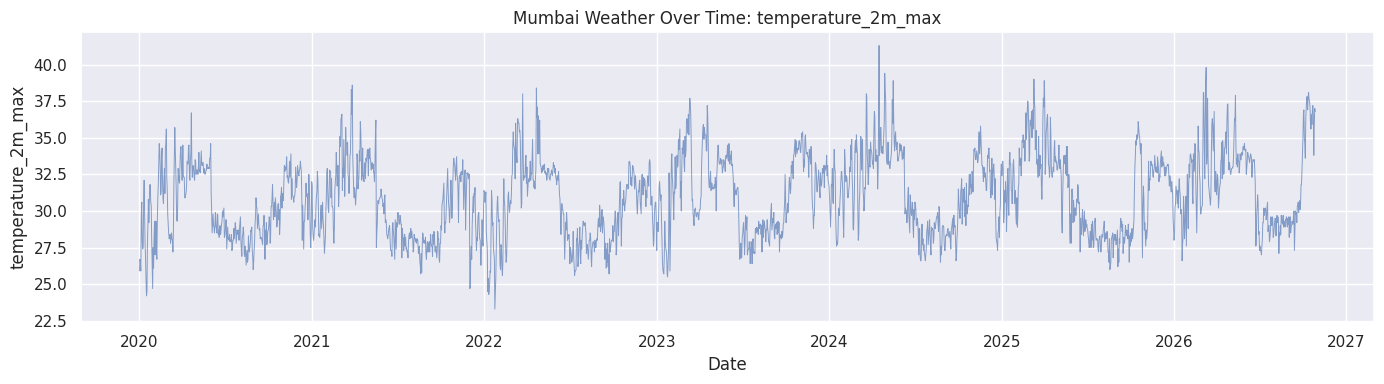

Inference: look for seasonal cycles and unusually high temperature periods. A climate trend claim requires consistent long-term coverage.


In [ ]:
if weather is not None and "date" in weather.columns and len(weather):
    wcols = {c.lower(): c for c in weather.columns}
    temp_cols = [wcols[c] for c in wcols if any(k in c for k in ["temperature_2m_max", "temp_max", "maximum_temperature", "tmax", "temperature_max"])]
    rain_cols = [wcols[c] for c in wcols if any(k in c for k in ["precipitation_sum", "rainfall", "precipitation", "rain_mm"])]
    if temp_cols:
        tc = temp_cols[0]
        plt.figure(figsize=(14, 4))
        plt.plot(weather["date"], pd.to_numeric(weather[tc], errors="coerce"), linewidth=0.7, alpha=0.65)
        plt.title(f"Mumbai Weather Over Time: {tc}")
        plt.xlabel("Date"); plt.ylabel(tc); plt.tight_layout(); plt.show()
        print("Inference: look for seasonal cycles and unusually high temperature periods. A climate trend claim requires consistent long-term coverage.")
    elif rain_cols:
        rc = rain_cols[0]
        plt.figure(figsize=(14, 4))
        plt.plot(weather["date"], pd.to_numeric(weather[rc], errors="coerce"), linewidth=0.7)
        plt.title(f"Mumbai Weather Over Time: {rc}")
        plt.xlabel("Date"); plt.ylabel(rc); plt.tight_layout(); plt.show()
        print("Inference: rainfall is expected to be seasonal in Mumbai; compare peaks across years and verify the unit/aggregation.")
    else:
        print("Weather data loaded, but no recognized temperature/rainfall field found. Inspect columns printed in Section 7.")
else: print("Skipped: no usable weather table.")

## Visualization 7 — AQI versus weather
**Purpose:** assess whether AQI varies with a weather measure on matching dates. Only dates available in both datasets are used; association is not causation.

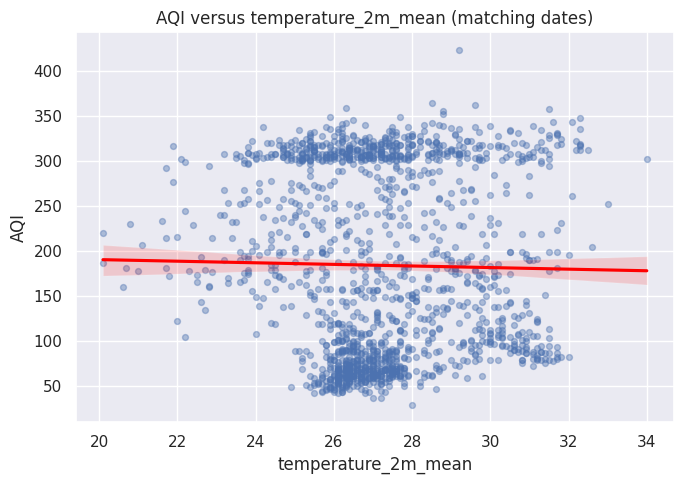

Matching daily records: 1545
Pearson correlation (temperature_2m_mean, AQI): -0.018
Inference: this is a same-date association in the available records, not evidence that weather caused AQI changes.


In [ ]:
if aqi is not None and weather is not None and "date" in aqi.columns and "date" in weather.columns and "AQI" in aqi.columns:
    preferred_weather = ["temperature_2m_mean", "temperature_2m_max", "temperature_2m_min",
                         "precipitation_sum", "relative_humidity_2m_mean", "wind_speed_10m_max"]
    wnum = [c for c in preferred_weather if c in weather.columns and pd.api.types.is_numeric_dtype(weather[c])]
    if not wnum:
        wnum = [c for c in weather.select_dtypes(include=np.number).columns
                if c.lower() not in ["latitude", "longitude", "elevation_m"]]
    merged_aw = aqi[["date","AQI"]].merge(weather[["date"]+wnum], on="date", how="inner").dropna(subset=["AQI"])
    if wnum and len(merged_aw) > 5:
        wc = wnum[0]
        merged_aw[wc] = pd.to_numeric(merged_aw[wc], errors="coerce")
        plot_df = merged_aw[["AQI",wc]].dropna()
        if len(plot_df) > 5:
            plt.figure(figsize=(7, 5))
            sns.regplot(data=plot_df, x=wc, y="AQI", scatter_kws={"alpha":0.4, "s":18}, line_kws={"color":"red"})
            plt.title(f"AQI versus {wc} (matching dates)")
            plt.tight_layout(); plt.show()
            print(f"Matching daily records: {len(plot_df)}")
            print(f"Pearson correlation ({wc}, AQI):", round(plot_df[wc].corr(plot_df["AQI"]), 3))
            print("Inference: this is a same-date association in the available records, not evidence that weather caused AQI changes.")
        else: print("Skipped: too few complete paired observations.")
    else: print("Skipped: no common numeric weather variable or insufficient matching dates.")
else: print("Skipped: need both AQI and weather data with date and AQI columns.")

## Visualization 8 — Missing data by variable
**Purpose:** show which fields have the weakest data coverage. This is important before modelling or drawing citywide conclusions.

In [ ]:
if aqi is not None:
    miss = (aqi.isna().mean()*100).sort_values(ascending=False)
    miss = miss[miss > 0]
    if len(miss):
        plt.figure(figsize=(10, max(3, 0.35*len(miss))))
        sns.barplot(x=miss.values, y=miss.index)
        plt.title("Missing Values in Mumbai AQI Dataset")
        plt.xlabel("Missing records (%)"); plt.ylabel("Field"); plt.tight_layout(); plt.show()
        print("Inference: features with high missingness may not be suitable for models without careful handling. Missingness may reflect monitoring/data collection changes.")
    else: print("No missing values found in the loaded AQI table.")
else: print("Skipped: AQI data not loaded.")

No missing values found in the loaded AQI table.


## Visualization 9 — Isolation Forest anomaly detection


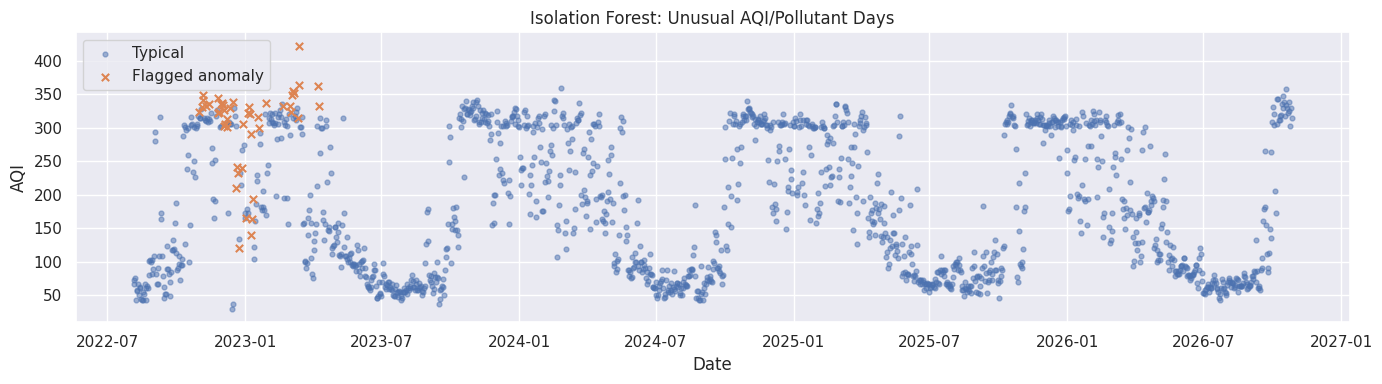

Flagged observations: 47 of 1545


,date,AQI,PM2.5,PM10,NO2,SO2,CO,O3,anomaly_label,anomaly_score
45025,2023-03-13,423,279.78,403.34,116.25,144.52,2912.38,715.88,-1,-0.169525
45026,2023-03-14,364,202.74,293.63,50.28,137.58,2397.38,475.62,-1,-0.144100
45016,2023-03-04,349,171.42,250.03,69.35,170.02,2041.12,475.00,-1,-0.130007
44918,2022-11-26,345,178.23,258.33,99.89,157.78,1891.50,394.50,-1,-0.127501
45017,2023-03-05,355,191.64,277.38,59.85,142.81,1846.50,429.12,-1,-0.126902
45051,2023-04-08,362,140.00,205.04,100.82,115.83,2237.25,540.12,-1,-0.115807
44981,2023-01-28,337,157.22,230.05,89.50,155.94,1887.62,408.50,-1,-0.106926
44922,2022-11-30,335,159.17,229.78,105.40,129.03,1942.00,397.38,-1,-0.102493
44919,2022-11-27,324,147.36,213.57,96.15,169.95,1936.88,335.25,-1,-0.099141
44926,2022-12-04,327,153.83,222.29,102.70,124.85,1982.00,353.38,-1,-0.092386


Inference: flagged rows are statistically unusual relative to the selected features. Validate against source records, weather, local events, and station coverage before assigning a cause.


In [ ]:
anomaly_df = None
if aqi is not None:
    features = [c for c in ["AQI","PM2.5","PM10","NO2","SO2","CO","O3"] if c in aqi.columns and pd.api.types.is_numeric_dtype(aqi[c])]
    if len(features) >= 2 and len(aqi.dropna(subset=features)) >= 30:
        model_df = aqi[["date"]+features].dropna().copy()
        iso = IsolationForest(contamination=0.03, random_state=RANDOM_STATE)
        model_df["anomaly_label"] = iso.fit_predict(model_df[features])
        model_df["anomaly_score"] = iso.decision_function(model_df[features])
        anomaly_df = model_df
        plt.figure(figsize=(14, 4))
        normal = model_df["anomaly_label"] == 1
        plt.scatter(model_df.loc[normal,"date"], model_df.loc[normal,"AQI"], s=12, alpha=0.5, label="Typical")
        plt.scatter(model_df.loc[~normal,"date"], model_df.loc[~normal,"AQI"], s=28, marker="x", label="Flagged anomaly")
        plt.title("Isolation Forest: Unusual AQI/Pollutant Days")
        plt.xlabel("Date"); plt.ylabel("AQI"); plt.legend(); plt.tight_layout(); plt.show()
        print("Flagged observations:", int((model_df["anomaly_label"] == -1).sum()), "of", len(model_df))
        display(model_df.loc[model_df["anomaly_label"] == -1].sort_values("anomaly_score").head(10))
        print("Inference: flagged rows are statistically unusual relative to the selected features. Validate against source records, weather, local events, and station coverage before assigning a cause.")
    else: print("Skipped: need at least two pollutant/AQI features and 30 complete rows.")
else: print("Skipped: AQI data not loaded.")

## Visualization 10 — Time-series decomposition


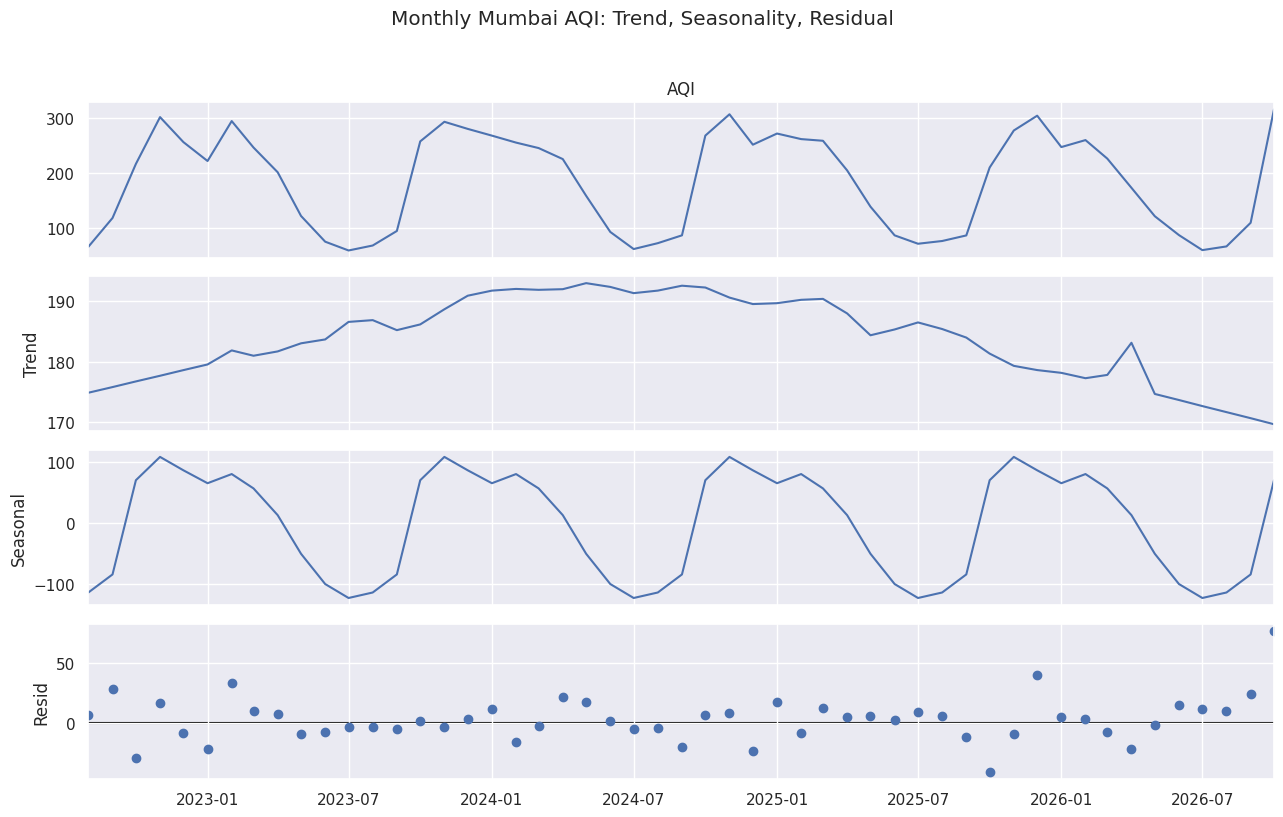

Inference: trend represents slower movement, seasonal component represents recurring calendar-month patterns, and residual captures what remains. Interpolated gaps can affect the decomposition.


In [ ]:
monthly_aqi = None
if aqi is not None and "AQI" in aqi.columns and aqi["AQI"].notna().sum() >= 24:
    monthly_aqi = aqi.set_index("date")["AQI"].resample("MS").mean().dropna()
    if len(monthly_aqi) >= 24:
        # Fill gaps only for decomposition continuity; disclose interpolation.
        monthly_regular = monthly_aqi.asfreq("MS")
        monthly_filled = monthly_regular.interpolate(limit=2)
        if monthly_filled.notna().sum() >= 24 and monthly_filled.isna().sum() == 0:
            try:
                decomp = seasonal_decompose(monthly_filled, model="additive", period=12, extrapolate_trend="freq")
                fig = decomp.plot()
                fig.set_size_inches(13, 8)
                fig.suptitle("Monthly Mumbai AQI: Trend, Seasonality, Residual", y=1.02)
                plt.tight_layout(); plt.show()
                print("Inference: trend represents slower movement, seasonal component represents recurring calendar-month patterns, and residual captures what remains. Interpolated gaps can affect the decomposition.")
            except Exception as e:
                print("Decomposition could not be computed:", e)
        else: print("Skipped: too many missing monthly periods to safely decompose.")
    else: print("Skipped: need at least 24 monthly AQI observations.")
else: print("Skipped: insufficient AQI observations for decomposition.")

# Statistical and Machine Learning
## 9. Correlation analysis and simple linear regression


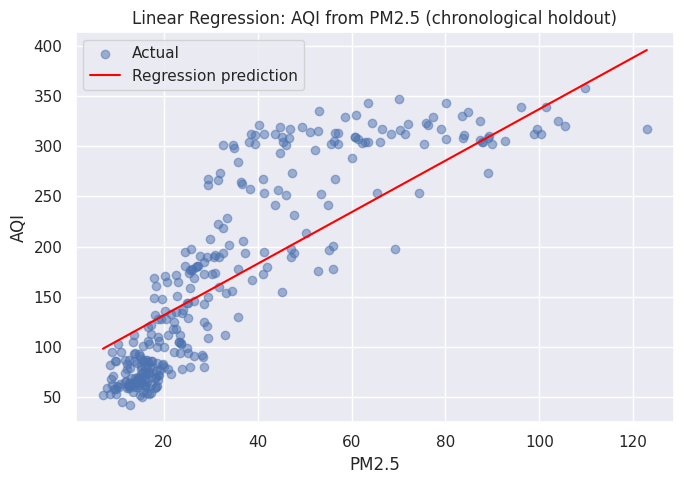

,feature,n_train,n_test,MAE,RMSE,R2,slope,intercept
0,PM2.5,1236,309,45.757,54.958,0.688,2.564,80.527


Inference: use MAE/RMSE to describe prediction error in AQI units. R² is the fraction of test-set variance explained; it is not a causal measure.


In [ ]:
regression_results = None
if aqi is not None and "AQI" in aqi.columns:
    predictors = [c for c in ["PM2.5","PM10","NO2","CO","SO2","O3"] if c in aqi.columns and pd.api.types.is_numeric_dtype(aqi[c])]
    if predictors:
        feature = predictors[0]
        reg = aqi[[feature,"AQI"]].dropna()
        if len(reg) >= 20:
            X = reg[[feature]].values
            y = reg["AQI"].values
            split = int(len(reg)*0.8)
            model = LinearRegression().fit(X[:split], y[:split])
            pred = model.predict(X[split:])
            regression_results = {
                "feature": feature,
                "n_train": split,
                "n_test": len(y)-split,
                "MAE": mean_absolute_error(y[split:], pred),
                "RMSE": mean_squared_error(y[split:], pred)**0.5,
                "R2": r2_score(y[split:], pred),
                "slope": float(model.coef_[0]),
                "intercept": float(model.intercept_)
            }
            plt.figure(figsize=(7,5))
            plt.scatter(X[split:], y[split:], alpha=0.5, label="Actual")
            order = np.argsort(X[split:,0])
            plt.plot(X[split:,0][order], pred[order], color="red", label="Regression prediction")
            plt.title(f"Linear Regression: AQI from {feature} (chronological holdout)")
            plt.xlabel(feature); plt.ylabel("AQI"); plt.legend(); plt.tight_layout(); plt.show()
            display(pd.DataFrame([regression_results]).round(3))
            print("Inference: use MAE/RMSE to describe prediction error in AQI units. R² is the fraction of test-set variance explained; it is not a causal measure.")
        else: print("Skipped: not enough complete rows for regression.")
    else: print("Skipped: no recognized numeric pollutant predictor.")
else: print("Skipped: AQI data not loaded.")

## 10. ADF stationarity test and first differencing
**Relevant lab mapping:** ADF test and differencing from time-series experiments. The null hypothesis of ADF is that a unit root is present (non-stationarity). A p-value below 0.05 is evidence against that null, not proof that every modelling assumption is satisfied.

,series,ADF statistic,p-value,lags,observations
0,Monthly AQI level,-1.4497,0.5582,11,39
1,First difference,-8.6006,0.0000,10,39


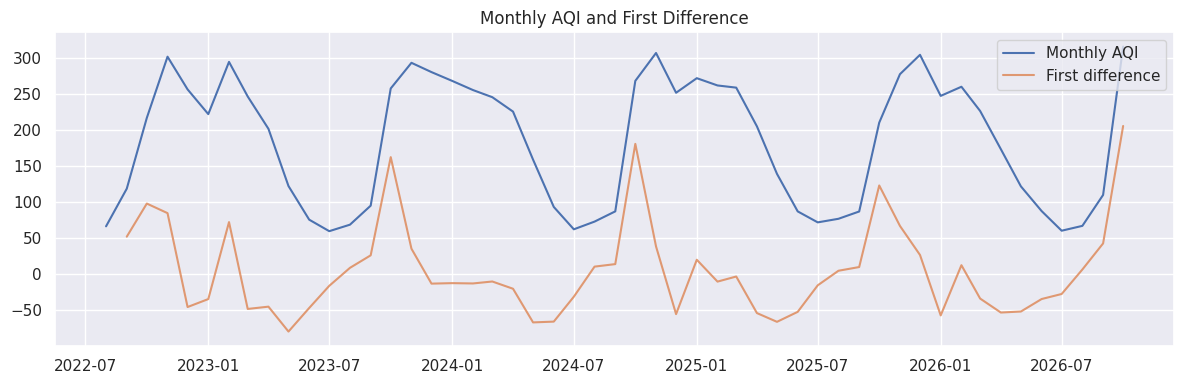

Inference: compare ADF p-values before/after differencing. A lower p-value after differencing suggests the differenced series is more stationary under this test.


In [ ]:
if monthly_aqi is not None and len(monthly_aqi) >= 12:
    series = monthly_aqi.asfreq("MS").interpolate(limit_direction="both")
    try:
        adf_original = adfuller(series.dropna(), autolag="AIC")
        diff_series = series.diff().dropna()
        adf_diff = adfuller(diff_series, autolag="AIC")
        display(pd.DataFrame([
            {"series":"Monthly AQI level","ADF statistic":adf_original[0],"p-value":adf_original[1],"lags":adf_original[2],"observations":adf_original[3]},
            {"series":"First difference","ADF statistic":adf_diff[0],"p-value":adf_diff[1],"lags":adf_diff[2],"observations":adf_diff[3]}
        ]).round(4))
        fig, ax = plt.subplots(figsize=(12,4))
        ax.plot(series.index, series.values, label="Monthly AQI")
        ax.plot(diff_series.index, diff_series.values, label="First difference", alpha=0.8)
        ax.set_title("Monthly AQI and First Difference")
        ax.legend(); plt.tight_layout(); plt.show()
        print("Inference: compare ADF p-values before/after differencing. A lower p-value after differencing suggests the differenced series is more stationary under this test.")
    except Exception as e: print("ADF test failed:", e)
else: print("Skipped: monthly AQI series unavailable.")

## 11. Forecasting benchmark — naive baseline vs Holt–Winters


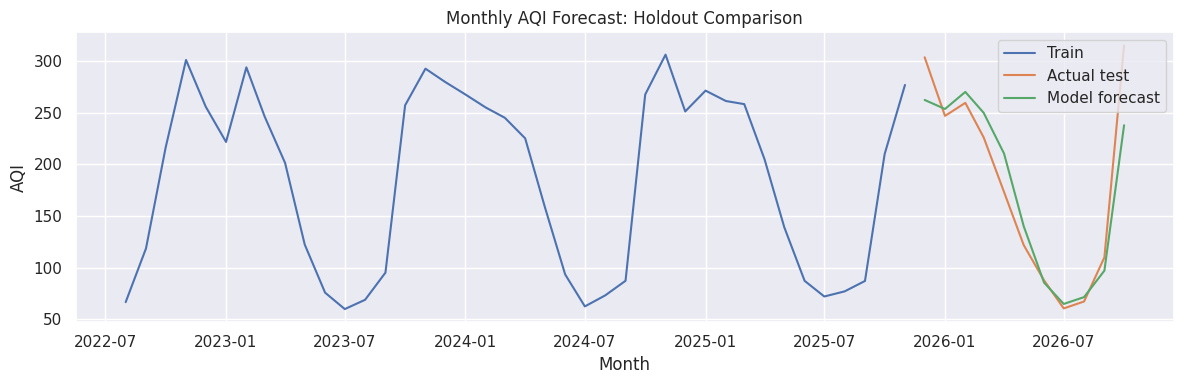

,model,MAE,RMSE
1,Holt-Winters / Exponential Smoothing,21.742,30.683
0,Naive last value,109.650,133.442


Inference: lower MAE/RMSE is better on this holdout. A model that beats the naive baseline is useful evidence, but a single split is not enough to claim reliable operational forecasting.


In [ ]:
forecast_metrics = []
if monthly_aqi is not None and len(monthly_aqi) >= 24:
    y = monthly_aqi.asfreq("MS")
    y = y.interpolate(limit=2).dropna()
    split = int(len(y)*0.8)
    train, test = y.iloc[:split], y.iloc[split:]
    if len(test) >= 3 and len(train) >= 18:
        # Baseline: repeat last training observation
        naive_pred = np.repeat(train.iloc[-1], len(test))
        forecast_metrics.append({
            "model":"Naive last value",
            "MAE":mean_absolute_error(test, naive_pred),
            "RMSE":mean_squared_error(test, naive_pred)**0.5
        })
        try:
            if len(train) >= 24:
                hw = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12, initialization_method="estimated").fit(optimized=True)
            else:
                hw = ExponentialSmoothing(train, trend="add", initialization_method="estimated").fit(optimized=True)
            hw_pred = hw.forecast(len(test))
            forecast_metrics.append({
                "model":"Holt-Winters / Exponential Smoothing",
                "MAE":mean_absolute_error(test, hw_pred),
                "RMSE":mean_squared_error(test, hw_pred)**0.5
            })
            plt.figure(figsize=(12,4))
            plt.plot(train.index, train.values, label="Train")
            plt.plot(test.index, test.values, label="Actual test")
            plt.plot(test.index, hw_pred.values, label="Model forecast")
            plt.title("Monthly AQI Forecast: Holdout Comparison")
            plt.xlabel("Month"); plt.ylabel("AQI"); plt.legend(); plt.tight_layout(); plt.show()
        except Exception as e:
            print("Exponential smoothing could not be fit:", e)
        metrics_df = pd.DataFrame(forecast_metrics).sort_values("RMSE")
        display(metrics_df.round(3))
        print("Inference: lower MAE/RMSE is better on this holdout. A model that beats the naive baseline is useful evidence, but a single split is not enough to claim reliable operational forecasting.")
    else: print("Skipped: not enough train/test observations.")
else: print("Skipped: need at least 24 monthly AQI observations.")

# 12. Rainfall and Transport

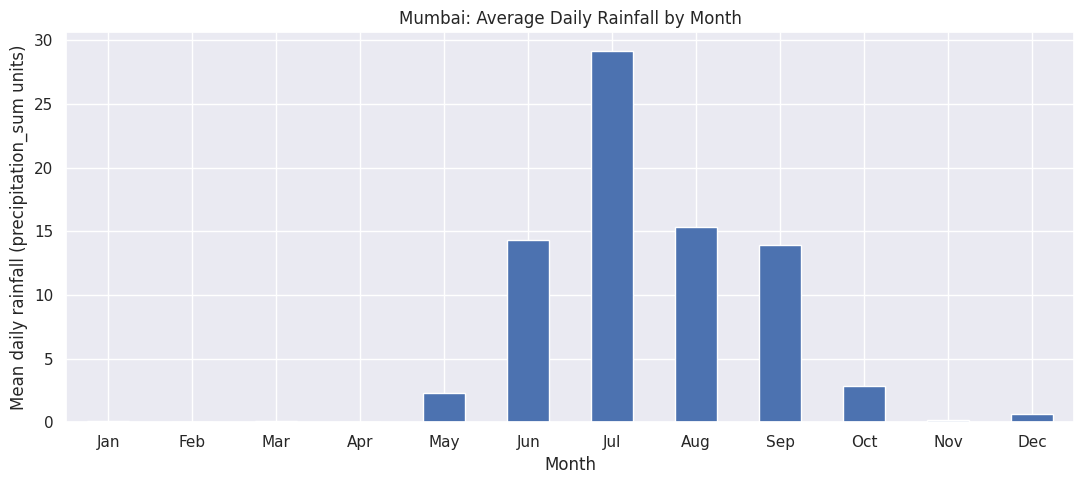

Wettest month by average daily rainfall: 7 with 29.17
Driest month by average daily rainfall: 2 with 0.01
Inference: this visual identifies seasonal rainfall patterns in the available weather dataset.
It does not, by itself, identify flood events or prove flood risk.


In [ ]:
# Monthly rainfall trends and seasonal pattern

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Existing notebook variable: weather
rain_col = next(
    (c for c in weather.columns
     if any(k in c.lower() for k in ["precipitation_sum", "rainfall", "rain_mm"])),
    None
)

if rain_col is None:
    print("No rainfall column found. Available columns:", weather.columns.tolist())
else:
    rain = weather[["date", rain_col]].copy()
    rain["date"] = pd.to_datetime(rain["date"], errors="coerce")
    rain[rain_col] = pd.to_numeric(rain[rain_col], errors="coerce")
    rain = rain.dropna().sort_values("date")
    rain["year"] = rain["date"].dt.year
    rain["month"] = rain["date"].dt.month

    # Average daily rainfall for each calendar month
    monthly_rain = rain.groupby("month")[rain_col].mean().reindex(range(1, 13))

    plt.figure(figsize=(11, 5))
    monthly_rain.plot(kind="bar")
    plt.title("Mumbai: Average Daily Rainfall by Month")
    plt.xlabel("Month")
    plt.ylabel(f"Mean daily rainfall ({rain_col} units)")
    plt.xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun",
                           "Jul","Aug","Sep","Oct","Nov","Dec"], rotation=0)
    plt.tight_layout()
    plt.show()

    wettest_month = monthly_rain.idxmax()
    driest_month = monthly_rain.idxmin()
    print("Wettest month by average daily rainfall:", wettest_month,
          "with", round(monthly_rain.max(), 2))
    print("Driest month by average daily rainfall:", driest_month,
          "with", round(monthly_rain.min(), 2))
    print("Inference: this visual identifies seasonal rainfall patterns in the available weather dataset.")
    print("It does not, by itself, identify flood events or prove flood risk.")

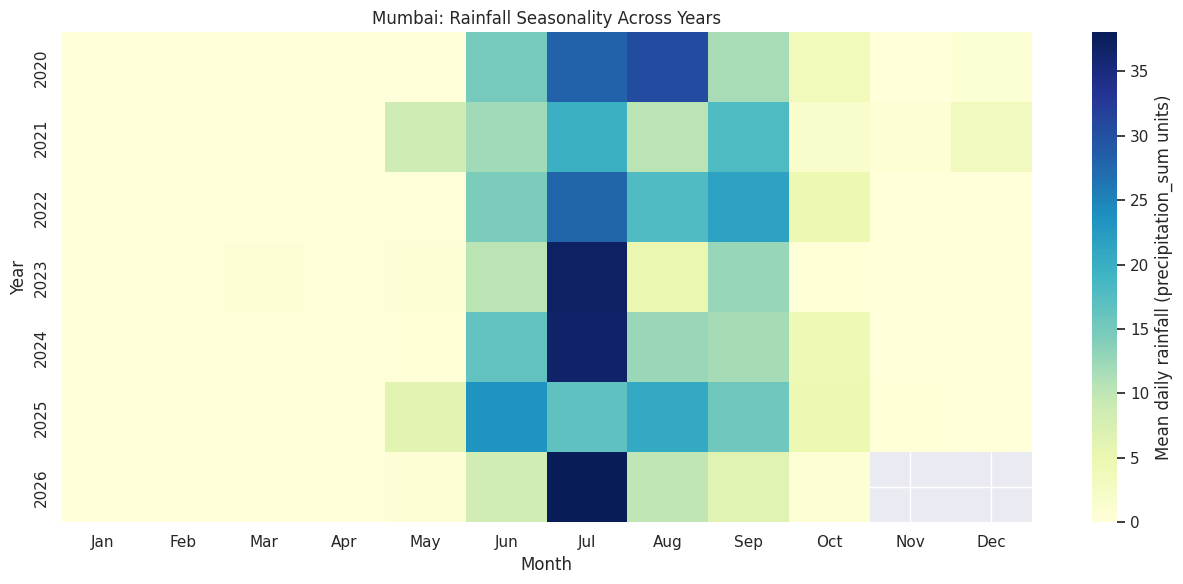

Inference: darker cells represent months with higher mean daily rainfall.
Check whether monsoon-season rainfall peaks recur across years.
Note: incomplete years may not be directly comparable.


In [ ]:
# Year-by-month rainfall heatmap

if rain_col is not None:
    rain_monthly = (
        rain.assign(year=rain["date"].dt.year,
                    month=rain["date"].dt.month)
        .groupby(["year", "month"])[rain_col]
        .mean()
        .unstack("month")
        .reindex(columns=range(1, 13))
    )

    plt.figure(figsize=(13, 6))
    sns.heatmap(rain_monthly, cmap="YlGnBu", annot=False,
                cbar_kws={"label": f"Mean daily rainfall ({rain_col} units)"})
    plt.title("Mumbai: Rainfall Seasonality Across Years")
    plt.xlabel("Month")
    plt.ylabel("Year")
    plt.xticks(np.arange(12) + 0.5,
               ["Jan","Feb","Mar","Apr","May","Jun",
                "Jul","Aug","Sep","Oct","Nov","Dec"], rotation=0)
    plt.tight_layout()
    plt.show()

    print("Inference: darker cells represent months with higher mean daily rainfall.")
    print("Check whether monsoon-season rainfall peaks recur across years.")
    print("Note: incomplete years may not be directly comparable.")

Saving b34111da-5b73-45e9-82d0-78da9d153b1c.kml to b34111da-5b73-45e9-82d0-78da9d153b1c (1).kml
Point features extracted: 6267


,name,longitude,latitude
0,"ELECTRIC HOUSE, COLABA DEPOT",72.830029,18.920099
1,"COLABA BUS STATION, POST OFFICE",72.820905,18.911184
2,DHOBI GHAT (NAVY NAGAR),72.812432,18.906977
3,DR. SHYAMAPRASAD MUKHERJEE CHOWK(MUSEUM),72.831553,18.926071
4,DR. SHYAMAPRASAD MUKHERJEE CHOWK(MUSEUM),72.831582,18.926225


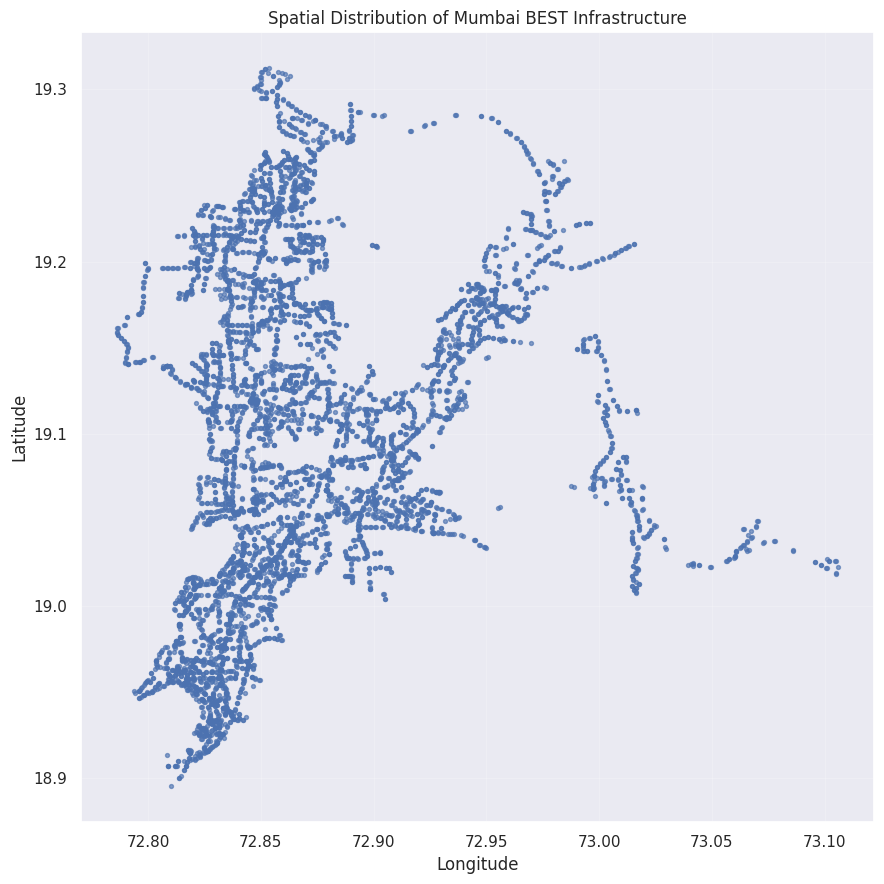

Inference: the map shows the spatial distribution of point features in the uploaded KML.
It does not measure service frequency, passenger demand, or neighbourhood coverage.


In [ ]:
# Upload and inspect the official/open-data BEST KML map

from google.colab import files
import xml.etree.ElementTree as ET
import pandas as pd
import matplotlib.pyplot as plt

uploaded = files.upload()  # Select the downloaded .kml file

kml_filename = next(
    (name for name in uploaded if name.lower().endswith(".kml")),
    None
)

if kml_filename is None:
    print("Please upload a .kml file downloaded from the linked BEST dataset.")
else:
    root = ET.fromstring(uploaded[kml_filename])
    ns = {"kml": "http://www.opengis.net/kml/2.2"}

    places = []
    for placemark in root.findall(".//kml:Placemark", ns):
        name_el = placemark.find("kml:name", ns)
        name = name_el.text.strip() if name_el is not None and name_el.text else "Unnamed location"

        # Extract coordinates from point geometries
        point = placemark.find(".//kml:Point/kml:coordinates", ns)
        if point is not None and point.text:
            try:
                lon, lat, *_ = map(float, point.text.strip().split(","))
                places.append({"name": name, "longitude": lon, "latitude": lat})
            except ValueError:
                pass

    best_places = pd.DataFrame(places)

    print("Point features extracted:", len(best_places))
    display(best_places.head())

    if not best_places.empty:
        plt.figure(figsize=(9, 9))
        plt.scatter(best_places["longitude"], best_places["latitude"], s=8, alpha=0.65)
        plt.title("Spatial Distribution of Mumbai BEST Infrastructure")
        plt.xlabel("Longitude")
        plt.ylabel("Latitude")
        plt.grid(alpha=0.2)
        plt.tight_layout()
        plt.show()

        print("Inference: the map shows the spatial distribution of point features in the uploaded KML.")
        print("It does not measure service frequency, passenger demand, or neighbourhood coverage.")
    else:
        print("No point geometries were found. The KML may contain lines or polygons instead.")
        print("Inspect the downloaded file or use the BMC interactive transport map.")

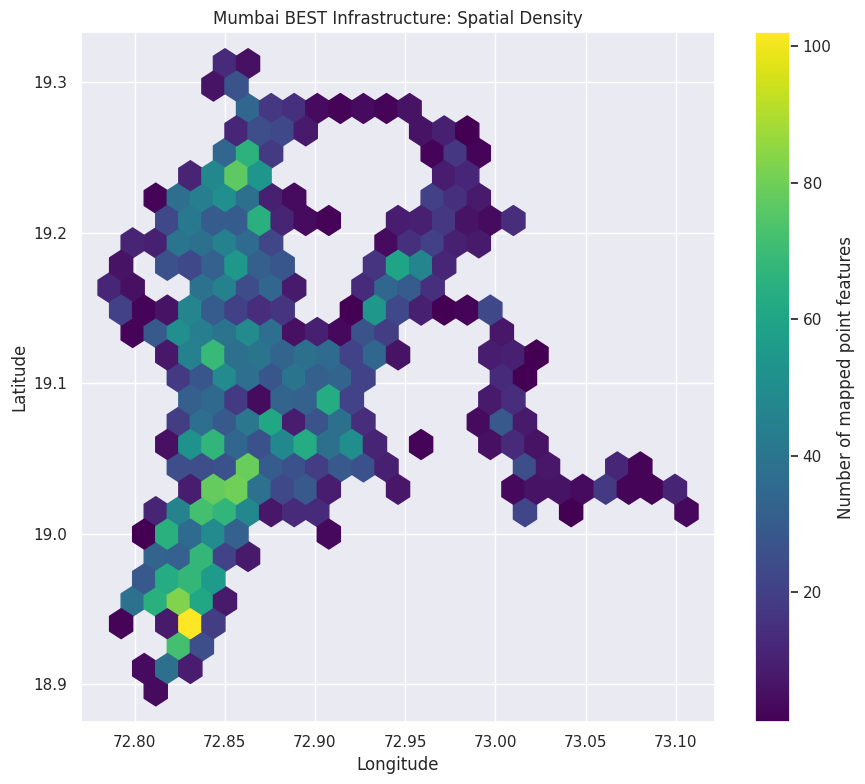

Inference: denser cells contain more mapped point features.
This is a spatial distribution view, not a measure of transport accessibility.


In [ ]:
# Spatial density of mapped BEST locations

if "best_places" in globals() and not best_places.empty:
    plt.figure(figsize=(9, 8))
    plt.hexbin(
        best_places["longitude"],
        best_places["latitude"],
        gridsize=25,
        mincnt=1,
        cmap="viridis"
    )
    plt.colorbar(label="Number of mapped point features")
    plt.title("Mumbai BEST Infrastructure: Spatial Density")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.tight_layout()
    plt.show()

    print("Inference: denser cells contain more mapped point features.")
    print("This is a spatial distribution view, not a measure of transport accessibility.")
else:
    print("Run Cell 3 successfully first to create best_places.")

Matching AQI-rainfall dates: 1545


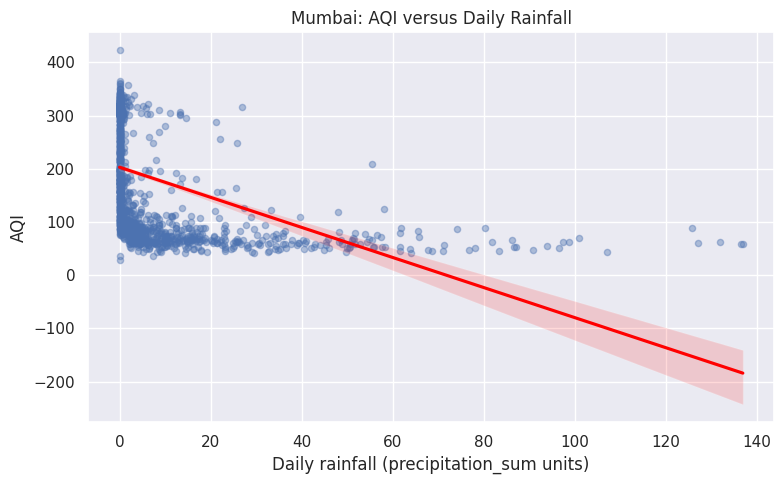

Pearson correlation between AQI and rainfall: -0.442
Inference: this measures association on matching dates, not causation.


In [ ]:
# AQI versus rainfall on matching dates

if "aqi" in globals() and "weather" in globals() and rain_col is not None:
    aqi_rain = aqi[["date", "AQI"]].copy()
    weather_rain = weather[["date", rain_col]].copy()

    aqi_rain["date"] = pd.to_datetime(aqi_rain["date"], errors="coerce")
    weather_rain["date"] = pd.to_datetime(weather_rain["date"], errors="coerce")

    aqi_rain["AQI"] = pd.to_numeric(aqi_rain["AQI"], errors="coerce")
    weather_rain[rain_col] = pd.to_numeric(weather_rain[rain_col], errors="coerce")

    aqi_rain = aqi_rain.dropna(subset=["date", "AQI"])
    weather_rain = weather_rain.dropna(subset=["date", rain_col])

    aqi_rain_merged = aqi_rain.merge(weather_rain, on="date", how="inner")
    aqi_rain_merged = aqi_rain_merged.dropna()

    print("Matching AQI-rainfall dates:", len(aqi_rain_merged))

    if len(aqi_rain_merged) > 5:
        plt.figure(figsize=(8, 5))
        sns.regplot(
            data=aqi_rain_merged,
            x=rain_col,
            y="AQI",
            scatter_kws={"alpha": 0.4, "s": 20},
            line_kws={"color": "red"}
        )
        plt.title("Mumbai: AQI versus Daily Rainfall")
        plt.xlabel(f"Daily rainfall ({rain_col} units)")
        plt.ylabel("AQI")
        plt.tight_layout()
        plt.show()

        corr = aqi_rain_merged["AQI"].corr(aqi_rain_merged[rain_col])
        print("Pearson correlation between AQI and rainfall:", round(corr, 3))
        print("Inference: this measures association on matching dates, not causation.")
    else:
        print("Not enough matching dates for a reliable comparison.")
else:
    print("Check that aqi, weather, and the rainfall column are available.")

# 13. SUMMARY

In [ ]:
# SUMMARY

print("=" * 55)
print("INTEGRATED SMART-CITY ANALYTICS FOR MUMBAI")
print("=" * 55)

print("1. Environmental health: AQI, pollutants, anomalies and forecasting")
print("2. Weather: temperature and weather trends")
print("3. Rainfall: monthly seasonality and year-month patterns")
print("4. Urban mobility: spatial distribution of mapped BEST infrastructure")
print("5. Cross-domain analysis: AQI versus rainfall on matching dates")

if "aqi_rain_merged" in globals():
    print("Matching AQI-rainfall observations:", len(aqi_rain_merged))

if "best_places" in globals():
    print("BEST point features extracted from KML:", len(best_places))

print("\nLimitations:")
print("- BEST infrastructure locations do not show passenger volumes or bus frequency.")
print("- Rainfall and AQI association does not establish causation.")
print("- The analysis covers only the dates and locations available in the source data.")

INTEGRATED SMART-CITY ANALYTICS FOR MUMBAI
1. Environmental health: AQI, pollutants, anomalies and forecasting
2. Weather: temperature and weather trends
3. Rainfall: monthly seasonality and year-month patterns
4. Urban mobility: spatial distribution of mapped BEST infrastructure
5. Cross-domain analysis: AQI versus rainfall on matching dates
Matching AQI-rainfall observations: 1545
BEST point features extracted from KML: 6267

Limitations:
- BEST infrastructure locations do not show passenger volumes or bus frequency.
- Rainfall and AQI association does not establish causation.
- The analysis covers only the dates and locations available in the source data.
